# 05 — Entrenamiento y comparación de modelos

Objetivo: comparar modelos candidatos con una metodología consistente antes de optimizar sus hiperparámetros.

## Carga de datos y preparación

Este bloque reproduce la división usada en los experimentos. Ejecutá el notebook desde la raíz del proyecto para que la ruta relativa funcione.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

df_fe = pd.read_csv("../data/processed/airbnb_dp.csv")

X = df_fe.drop(columns=["price"])
y = df_fe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (19140, 136)
X_test: (4786, 136)


## 1. Regresiones lineales

Entrenamiento y comparación inicial de modelos lineales. Las métricas registradas en test son exploratorias; para seleccionar modelos, priorizá validación cruzada sobre `X_train` e `y_train`.

## Regresiones lineales

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def model_pipeline(X_train, y_train, X_test, y_test):
    models = {
        "Linear Regression": {"model": LinearRegression(), "params": {}},
        "Ridge": {"model": Ridge(), "params": {"model__alpha": [0.1, 1, 10, 100]}},
        "Lasso": {
            "model": Lasso(max_iter=10000),
            "params": {"model__alpha": [0.1, 1, 10]},
        },
        "Elastic Net": {
            "model": ElasticNet(max_iter=10000),
            "params": {
                "model__alpha": [0.1, 1, 10],
                "model__l1_ratio": [0.2, 0.5, 0.8],
            },
        },
    }

    results = {}

    for name, info in models.items():
        pipeline = Pipeline([("scaler", StandardScaler()), ("model", info["model"])])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=info["params"],
            cv=5,
            scoring="r2",
            n_jobs=-1,
            verbose=1,
        )

        search.fit(X_train, y_train)
        predictions = search.predict(X_test)

        results[name] = {
            "Best Params": search.best_params_,
            "CV R2": search.best_score_,
            "Test R2": r2_score(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "MAE": mean_absolute_error(y_test, predictions),
        }

        print(f"{name}: terminado")

    return pd.DataFrame(results).T


resultados = model_pipeline(X_train, y_train, X_test, y_test)

display(resultados)


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Linear Regression: terminado
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Ridge: terminado
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Lasso: terminado
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Elastic Net: terminado


,Best Params,CV R2,Test R2,RMSE,MAE
Linear Regression,{},0.410434,0.412977,71397.775941,41230.905886
Ridge,{'model__alpha': 100},0.410708,0.412885,71403.397405,41209.872663
Lasso,{'model__alpha': 10},0.410677,0.413113,71389.510024,41217.641698
Elastic Net,"{'model__alpha': 0.1, 'model__l1_ratio': 0.8}",0.410689,0.412044,71454.467262,41177.134484


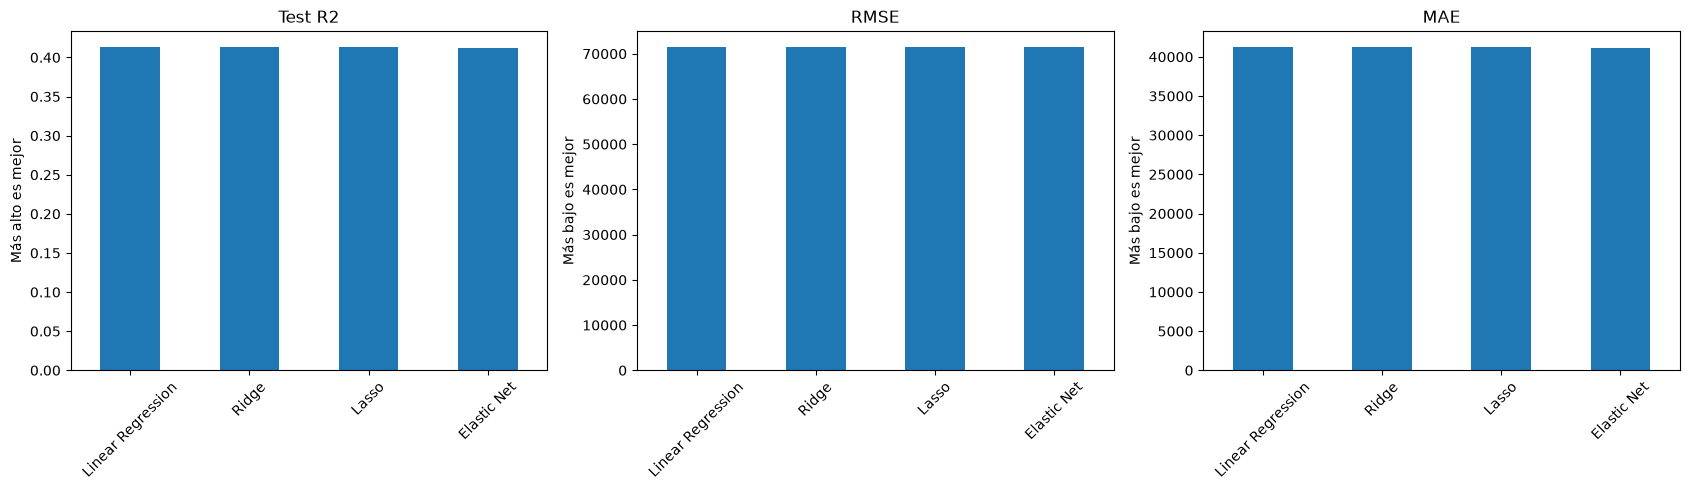

In [3]:
metricas = ["Test R2", "RMSE", "MAE"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metrica in zip(axes, metricas):
    resultados[metrica].plot(kind="bar", ax=ax)
    ax.set_title(metrica)
    ax.tick_params(axis="x", rotation=45)

    if metrica == "Test R2":
        ax.set_ylabel("Más alto es mejor")
    else:
        ax.set_ylabel("Más bajo es mejor")

plt.tight_layout()
plt.show()


## Modelos basados en árboles

In [4]:
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline


def model_pipeline_trees(X_train, y_train, X_test, y_test):

    models = {
        "Decision Tree": {
            "model": DecisionTreeRegressor(random_state=42),
            "params": {
                "model__max_depth": [5, 10, 20, None],
                "model__min_samples_split": [2, 10],
                "model__min_samples_leaf": [1, 5],
            },
        },
        "Random Forest": {
            "model": RandomForestRegressor(random_state=42, n_jobs=1),
            "params": {
                "model__n_estimators": [100, 200],
                "model__max_depth": [10, 20, None],
                "model__min_samples_leaf": [1, 5],
            },
        },
        "Extra Trees": {
            "model": ExtraTreesRegressor(random_state=42, n_jobs=1),
            "params": {
                "model__n_estimators": [100, 200],
                "model__max_depth": [10, 20, None],
                "model__min_samples_leaf": [1, 5],
            },
        },
        "Gradient Boosting": {
            "model": GradientBoostingRegressor(random_state=42),
            "params": {
                "model__n_estimators": [100, 200],
                "model__learning_rate": [0.05, 0.1],
                "model__max_depth": [2, 3],
                "model__min_samples_leaf": [1, 5],
            },
        },
        "Hist Gradient Boosting": {
            "model": HistGradientBoostingRegressor(random_state=42),
            "params": {
                "model__max_iter": [100, 200],
                "model__learning_rate": [0.05, 0.1],
                "model__max_leaf_nodes": [15, 31],
                "model__l2_regularization": [0, 1],
            },
        },
    }

    results = {}

    for name, info in models.items():
        print(f"\nEntrenando: {name}")

        pipeline = Pipeline([("model", info["model"])])

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=info["params"],
            cv=5,
            scoring="r2",
            n_jobs=-1,
            verbose=1,
        )

        grid_search.fit(X_train, y_train)

        best_model = grid_search.best_estimator_
        predictions = best_model.predict(X_test)

        results[name] = {
            "Best Params": grid_search.best_params_,
            "CV R2": grid_search.best_score_,
            "Test R2": r2_score(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "MAE": mean_absolute_error(y_test, predictions),
        }

        print("Mejores parámetros:", grid_search.best_params_)
        print("CV R²:", grid_search.best_score_)
        print("Test R²:", results[name]["Test R2"])
        print("RMSE:", results[name]["RMSE"])
        print("MAE:", results[name]["MAE"])

    return pd.DataFrame(results).T


resultados_trees = model_pipeline_trees(X_train, y_train, X_test, y_test)

display(resultados_trees)



Entrenando: Decision Tree
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Mejores parámetros: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}
CV R²: 0.4208136824847828
Test R²: 0.3888002268530656
RMSE: 72853.21362857711
MAE: 41260.03382650886

Entrenando: Random Forest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Mejores parámetros: {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
CV R²: 0.5226113840299716
Test R²: 0.5053980059328486
RMSE: 65536.77298040186
MAE: 35266.12260035584

Entrenando: Extra Trees
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Mejores parámetros: {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
CV R²: 0.5031947769271399
Test R²: 0.48452518870865047
RMSE: 66905.34980112757
MAE: 36128.980151313954

Entrenando: Gradient Boosting
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Mejores parámetros: {'mod

,Best Params,CV R2,Test R2,RMSE,MAE
Decision Tree,"{'model__max_depth': 5, 'model__min_samples_le...",0.420814,0.3888,72853.213629,41260.033827
Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.522611,0.505398,65536.77298,35266.1226
Extra Trees,"{'model__max_depth': None, 'model__min_samples...",0.503195,0.484525,66905.349801,36128.980151
Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.526892,0.49805,66021.773124,35815.084945
Hist Gradient Boosting,"{'model__l2_regularization': 0, 'model__learni...",0.532779,0.510012,65230.347637,34962.535717


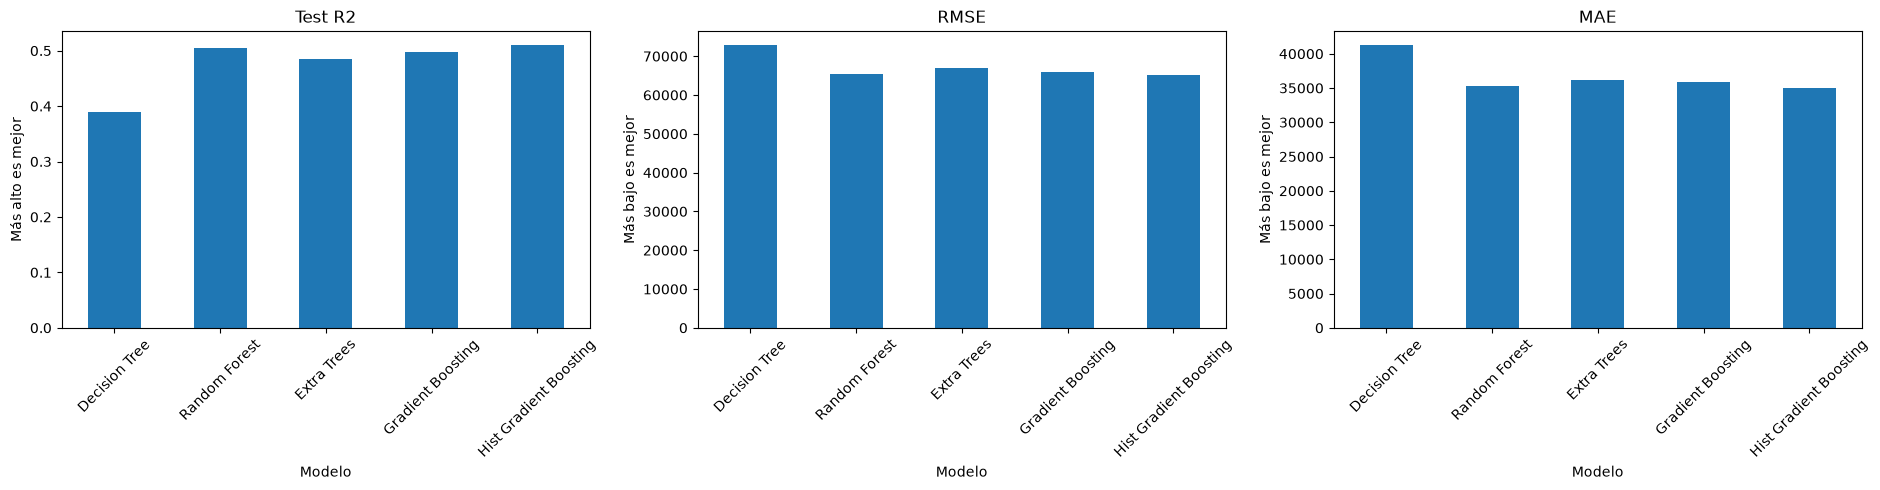

In [5]:
import matplotlib.pyplot as plt

metricas = ["Test R2", "RMSE", "MAE"]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, metrica in zip(axes, metricas):
    valores = resultados_trees[metrica].astype(float)

    valores.plot(kind="bar", ax=ax)

    ax.set_title(metrica)
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("Modelo")

    if metrica == "Test R2":
        ax.set_ylabel("Más alto es mejor")
    else:
        ax.set_ylabel("Más bajo es mejor")

plt.tight_layout()
plt.show()


## Otros modelos de regresion

In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import BayesianRidge, HuberRegressor, QuantileRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def model_pipeline_advanced(X_train, y_train, X_test, y_test):

    models = {
        "KNN": {
            "model": KNeighborsRegressor(),
            "params": {
                "model__n_neighbors": [5, 10, 20],
                "model__weights": ["uniform", "distance"],
                "model__p": [1, 2],
            },
        },
        "SVR": {
            "model": SVR(),
            "params": {
                "model__kernel": ["rbf"],
                "model__C": [1, 10, 100],
                "model__epsilon": [0.1, 0.5],
                "model__gamma": ["scale"],
            },
        },
        "MLP Regressor": {
            "model": MLPRegressor(max_iter=500, early_stopping=True, random_state=42),
            "params": {
                "model__hidden_layer_sizes": [(50,), (100,), (100, 50)],
                "model__alpha": [0.001, 0.01],
                "model__learning_rate_init": [0.001, 0.01],
            },
        },
        "Bayesian Ridge": {
            "model": BayesianRidge(),
            "params": {"model__alpha_1": [1e-6, 1e-5], "model__lambda_1": [1e-6, 1e-5]},
        },
        "Huber Regressor": {
            "model": HuberRegressor(max_iter=300),
            "params": {
                "model__epsilon": [1.35, 1.5, 2.0],
                "model__alpha": [0.0001, 0.01, 0.1],
            },
        },
        "Quantile Regression": {
            "model": QuantileRegressor(solver="highs"),
            "params": {
                "model__quantile": [0.25, 0.50, 0.75],
                "model__alpha": [0.01, 0.1, 1.0],
            },
        },
    }

    results = {}

    for name, info in models.items():
        print(f"\nEntrenando: {name}")

        pipeline = Pipeline([("scaler", StandardScaler()), ("model", info["model"])])

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=info["params"],
            cv=5,
            scoring="r2",
            n_jobs=-1,
            verbose=1,
        )

        grid.fit(X_train, y_train)

        best_model = grid.best_estimator_
        predictions = best_model.predict(X_test)

        results[name] = {
            "Best Params": grid.best_params_,
            "CV R2": grid.best_score_,
            "Test R2": r2_score(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "MAE": mean_absolute_error(y_test, predictions),
        }

        print("Mejores parámetros:", grid.best_params_)
        print("CV R²:", grid.best_score_)
        print("Test R²:", results[name]["Test R2"])
        print("RMSE:", results[name]["RMSE"])
        print("MAE:", results[name]["MAE"])

    return pd.DataFrame(results).T


resultados_advanced = model_pipeline_advanced(X_train, y_train, X_test, y_test)

display(resultados_advanced)



Entrenando: KNN
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Mejores parámetros: {'model__n_neighbors': 20, 'model__p': 1, 'model__weights': 'distance'}
CV R²: 0.4216326530056639
Test R²: 0.41330780563388414
RMSE: 71377.65513294091
MAE: 39628.55987138034

Entrenando: SVR
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Mejores parámetros: {'model__C': 100, 'model__epsilon': 0.5, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
CV R²: 0.027726603637246973
Test R²: 0.03211531592465233
RMSE: 91678.80215247792
MAE: 47841.86783459206

Entrenando: MLP Regressor
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Mejores parámetros: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (50,), 'model__learning_rate_init': 0.01}
CV R²: 0.4769739460725324
Test R²: 0.43238142846926964
RMSE: 70207.80894298056
MAE: 40076.67671235486

Entrenando: Bayesian Ridge
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Mejores parámetros: {'model__alpha_1': 1e-05

In [ ]:
import matplotlib.pyplot as plt

metricas = ["Test R2", "RMSE", "MAE"]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, metrica in zip(axes, metricas):
    valores = resultados_advanced[metrica].astype(float)

    valores.plot(kind="bar", ax=ax)

    ax.set_title(metrica)
    ax.set_xlabel("Modelo")
    ax.tick_params(axis="x", rotation=45)

    if metrica == "Test R2":
        ax.set_ylabel("Más alto es mejor")
    else:
        ax.set_ylabel("Más bajo es mejor")

plt.tight_layout()
plt.show()


## Conclusión y candidatos

Compará los resultados de los distintos grupos usando R² (más alto es mejor), RMSE y MAE (más bajos son mejores). Elegí un grupo pequeño de candidatos para el notebook 06. Evitá elegir repetidamente según el conjunto de test.